# 6 - Supplementary Figures S2 and S3

Both figures: the five task experiments as rows (Exp 1a, 1b, 2, 3, 5), two metrics as columns,
line plots only, in Figure 2's line-plot style (each axis the size of a Figure 2 line plot,
Arial 12 pt, panel letters A–J row by row, experiment name as each panel's title, one shared
legend below).

**Figure S2 — sound-locked median RT and d′** (all sounds, as Figures 2 and 4; −500…+1000 ms from
sound onset). `rt_median` is the median RT of the responded sounds in each window; `d_prime` is
signal-detection sensitivity. Y-ranges per experiment around its pre-sound level (mean over both
conditions, −500…0 ms): RT −100…+200 ms, d′ ±1 (`SOUND_YLIM_AROUND_BASELINE`). RT carries the
usual significance bars (FDR within RT); **d′ carries none** (`NO_SIG_METRICS`) — its estimates
are too volatile, with missing values and unequal samples, for a comparison with baseline. Grey
dashed line + band = the response (median RT, IQR).

**Figure S3 — response-locked saccade count and P(Correct Response)** (responded sounds only: a
sound with no response has no t = 0; −1000…+500 ms from the response):

| column | metric | y-axis |
|---|---|---|
| left | `saccade_count_normalized_spec` — % change from the **sound-locked** pre-sound baseline (−500…0 ms before the sound, responded sounds), since no response-locked window is pre-sound for every trial | one range shared by all five rows (`COUNT_YLIM`) |
| right | `p_correct_response` — on responded sounds identical to `p_correct_choice` | fitted per row to its curves, with headroom for the significance bars (`ACC_YLIM = None`) |

Congruent vs incongruent and each vs the sound-locked pre-sound baseline, FDR-corrected per metric
within each experiment. Black dashed line = the response (t = 0); grey dashed line + band = sound
onset (−median RT, −IQR). Exp 5 (`EX_11`) gets its exclusions from `src/exclusions.py`.

**Inputs**  the five experiments' preprocessed tables
**Outputs** `summaries/plots/figureS2.{png,pdf}`, `summaries/plots/figureS3.{png,pdf}`

**Caching — a routine run only plots.** `summaries/cache/figureS3_curves/` and
`summaries/cache/figureS2_curves/` hold each experiment's curves, RT and significance tests, keyed
on the analysis parameters, the data file's size/mtime and the source of `config.py`, `peri_sac.py`
(and `exclusions.py` for Exp 5), so they rebuild themselves after any of those change;
`FORCE_RECOMPUTE = True` forces it. Raw tables are read only when something must be recomputed.

In [1]:
%load_ext autoreload
%autoreload 2

import hashlib
import math
import os
import pickle
import sys
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

sys.path.insert(0, 'src')

import config
import peri_sac
import exclusions

importlib.reload(config)
importlib.reload(peri_sac)
importlib.reload(exclusions)

from peri_sac import (
    calculate_running_window_metrics,
    plot_single_condition,
    test_pairwise_conditions,
    test_condition_vs_baseline,
    calculate_baseline_metrics_from_trials,
    apply_fdr_correction,
    plot_significance_bars,
    DEFAULT_METRICS,
    COLOR_PALETTES,
)
from config import EXPERIMENT_CONFIGS, prepare_alternative_data, build_filter

%matplotlib inline
plt.rcParams['figure.dpi'] = 300
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

## Configuration

In [2]:
# ====================================================================
# EXPERIMENTS  (row order, top to bottom)
# ====================================================================

EXPERIMENTS = {
    'EX_1':  'Exp 1a. binaural-direction',
    'EX_9':  'Exp 1b. binaural-direction',
    'EX_7':  'Exp 2. monaural-direction',
    'EX_3':  'Exp 3. monaural-pitch',
    'EX_11': 'Exp 5. binaural-direction',
}


# ====================================================================
# ANALYSIS  (Figure S3: response-locked)
# ====================================================================

TIME_REFERENCE     = 'time_from_RT_to_sacc_start'     # 0 = the response
TIME_RANGE         = (-1000, 500)
BASELINE_REFERENCE = 'time_from_sound_to_sacc_start'  # baseline is always pre-sound, sound-locked
BASELINE_RANGE     = (-500, 0)
WINDOW_SIZE        = 100
STEP_SIZE          = 25
MIN_CORRECTION_N   = 5

COLUMNS = [   # (metric, y-label)
    ('saccade_count_normalized_spec', 'Saccade Count (% change)'),
    ('p_correct_response',            'P(Correct Response)'),
]

# Figure S2 - sound-locked, all sounds
SOUND_REFERENCE = 'time_from_sound_to_sacc_start'
SOUND_RANGE     = (-500, 1000)
SOUND_COLUMNS   = [   # (metric, y-label)
    ('rt_median', 'Median RT (ms)'),
    ('d_prime',   "d'"),
]
NO_SIG_METRICS  = {'d_prime'}          # drawn without significance bars
SOUND_YLIM_AROUND_BASELINE = {         # y-range = pre-sound level + these offsets
    'rt_median': (-100, 200),
    'd_prime':   (-1, 1),
}

# ====================================================================
# FIGURE
# ====================================================================

COUNT_YLIM   = (-60, 55)           # one range for all five rows; None = fitted (-59, 63: too much headroom)
COUNT_YTICKS = [-50, -25, 0, 25]   # None = three automatic ticks
ACC_YLIM     = None                # P(Correct Response): None = fitted per row (zoomed, as in the main figures); (0, 1) = 0-1 in every row
ACC_YTICKS   = [0, 0.5, 1]
YLIM_PAD     = (0.05, 0.30)        # fitted ranges: below / above the curves, as a fraction of their span
                                   # (the top margin holds the three significance-bar rows)

FONTSIZE      = 12
LINE_AX_W_IN  = 3.29               # a Figure 2 line plot (8.5 x 4.1 in cells, 2 x 2 grid)
LINE_AX_H_IN  = 2.63
GAP_W_IN      = 1.35               # room for the right column's y label and panel letter
GAP_H_IN      = 1.25               # room for x label, title and panel letter
FIG2_WIDTH_IN = 14.41              # Figure 2 PNG width (tight crop at 300 dpi)

OUTPUT_PATH = Path('summaries') / 'plots'
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)
CURVE_CACHE_DIR = Path('summaries') / 'cache' / 'figureS3_curves'
SOUND_CURVE_CACHE_DIR = Path('summaries') / 'cache' / 'figureS2_curves'
FORCE_RECOMPUTE = False

## Curves, RT and statistics per experiment (cached)

In [3]:
CONDITIONS = [('consistent', True), ('inconsistent', False)]


def load_table(exp):
    data_file = EXPERIMENT_CONFIGS[exp].get('data_file', 'long_format_alt_all.csv')
    data_raw = pd.read_csv(os.path.join(f'data_preprocessed/{exp}', data_file), low_memory=False)
    data = prepare_alternative_data(data_raw, sound_selection='both')
    if exp == 'EX_11':
        data, _ = exclusions.apply_exp5_exclusions(data)   # reversed blocks, then E11004 / E11010
    return data


_tables = {}

def table(exp):
    '''The prepared table, read from disk once per experiment and only when needed.'''
    if exp not in _tables:
        _tables[exp] = load_table(exp)
    return _tables[exp]


def significance(data, filters, results, metric):
    '''Congruent vs incongruent and each vs the sound-locked pre-sound baseline (on the responded
    subset), FDR-corrected as one family per metric.'''
    cols = ['id_subject', 'window_center', metric]
    merged = (results['consistent'][cols].rename(columns={metric: f'{metric}_cond0'})
              .merge(results['inconsistent'][cols].rename(columns={metric: f'{metric}_cond1'}),
                     on=['id_subject', 'window_center'], how='outer'))
    centres = merged['window_center'].dropna().unique()
    sig = {f'{metric}_cond0_vs_cond1': []}
    for wc in centres:
        r = test_pairwise_conditions(merged[merged['window_center'] == wc], metric, '_cond0', '_cond1')
        r['window_center'] = wc
        sig[f'{metric}_cond0_vs_cond1'].append(r)
    for ci, (cond, _) in enumerate(CONDITIONS):
        bd = calculate_baseline_metrics_from_trials(data[filters[cond]], BASELINE_RANGE, BASELINE_REFERENCE)
        key = f'{metric}_cond{ci}_vs_baseline'
        sig[key] = []
        for wc in centres:
            r = test_condition_vs_baseline(merged[merged['window_center'] == wc], bd, metric,
                                           metric_suffix=f'_cond{ci}', baseline_range=BASELINE_RANGE,
                                           window_size=WINDOW_SIZE)
            r['window_center'] = wc
            sig[key].append(r)
    return apply_fdr_correction(sig)


def compute(exp):
    print(f'=== {exp}: computing response-locked ===')
    data = table(exp)
    base = build_filter(data, include_response=True) & (data['response_given'] == 1)
    filters = {c: base & (data['consistent'] == v) for c, v in CONDITIONS}
    sdt_column = EXPERIMENT_CONFIGS[exp].get('sdt_column')
    results = {c: calculate_running_window_metrics(
                   data, filters[c], TIME_REFERENCE, window_size=WINDOW_SIZE, step_size=STEP_SIZE,
                   time_range=TIME_RANGE, baseline_range=BASELINE_RANGE,   # -> the _spec count
                   sdt_column=sdt_column, sdt_min_correction_n=MIN_CORRECTION_N)
               for c, _ in CONDITIONS}
    # Median RT and IQR - as in Figures 2 and 4 (responded rows, rt > 0)
    rt = data.loc[build_filter(data) & (data['response_given'] == 1) & (data['rt'] > 0), 'rt']
    # Pre-sound P(correct) on the responded subset, for the dotted reference line
    bl = calculate_running_window_metrics(
        data, base, BASELINE_REFERENCE, window_size=WINDOW_SIZE * 2, step_size=STEP_SIZE * 2,
        time_range=BASELINE_RANGE, baseline_range=BASELINE_RANGE)
    return {
        'results': results,
        'sig': {m: significance(data, filters, results, m) for m, _ in COLUMNS},
        'rt': (float(rt.median()), float(rt.quantile(0.25)), float(rt.quantile(0.75))),
        'pcr_centre': float(bl.loc[bl['window_center'].between(*BASELINE_RANGE),
                                   'p_correct_response'].dropna().mean()),
        'n_subjects': int(data.loc[base, 'id_subject'].nunique()),
    }


def cache_key(exp):
    data_file = Path(f'data_preprocessed/{exp}') / EXPERIMENT_CONFIGS[exp].get('data_file', 'long_format_alt_all.csv')
    st = data_file.stat()
    h = hashlib.sha256(repr((exp, TIME_REFERENCE, TIME_RANGE, BASELINE_REFERENCE, BASELINE_RANGE,
                             WINDOW_SIZE, STEP_SIZE, MIN_CORRECTION_N, COLUMNS,
                             str(data_file), st.st_size, st.st_mtime_ns)).encode())
    modules = ['src/config.py', 'src/peri_sac.py']
    if exp == 'EX_11':
        modules.append('src/exclusions.py')   # holds Exp 5's exclusion settings
    for m in modules:
        h.update(Path(m).read_bytes())
    return h.hexdigest()[:16]


CURVE_CACHE_DIR.mkdir(parents=True, exist_ok=True)
bundles = {}
for exp in EXPERIMENTS:
    path = CURVE_CACHE_DIR / f'{exp}_{cache_key(exp)}.pkl'
    if path.exists() and not FORCE_RECOMPUTE:
        with open(path, 'rb') as f:
            bundles[exp] = pickle.load(f)
    else:
        bundles[exp] = compute(exp)
        for stale in CURVE_CACHE_DIR.glob(f'{exp}_*.pkl'):
            stale.unlink()
        with open(path, 'wb') as f:
            pickle.dump(bundles[exp], f, protocol=pickle.HIGHEST_PROTOCOL)

# ── Sound-locked layer (Figure S2) ──────────────────────────────────
def compute_sound(exp):
    print(f'=== {exp}: computing sound-locked ===')
    data = table(exp)
    base = build_filter(data)                                   # all sounds, as Figures 2 and 4
    filters = {c: base & (data['consistent'] == v) for c, v in CONDITIONS}
    sdt_column = EXPERIMENT_CONFIGS[exp].get('sdt_column')
    results = {c: calculate_running_window_metrics(
                   data, filters[c], SOUND_REFERENCE, window_size=WINDOW_SIZE, step_size=STEP_SIZE,
                   time_range=SOUND_RANGE, baseline_range=BASELINE_RANGE,
                   sdt_column=sdt_column, sdt_min_correction_n=MIN_CORRECTION_N)
               for c, _ in CONDITIONS}
    # pre-sound level = mean over both conditions' baseline windows
    combined = pd.concat(results.values())
    in_bl = combined['window_center'].between(*BASELINE_RANGE)
    return {
        'results': results,
        'sig': {m: significance(data, filters, results, m)
                for m, _ in SOUND_COLUMNS if m not in NO_SIG_METRICS},
        'centre': {m: float(combined.loc[in_bl, m].dropna().mean()) for m, _ in SOUND_COLUMNS},
    }


def sound_cache_key(exp):
    return hashlib.sha256(repr((cache_key(exp), SOUND_REFERENCE, SOUND_RANGE, SOUND_COLUMNS,
                                sorted(NO_SIG_METRICS))).encode()).hexdigest()[:16]


SOUND_CURVE_CACHE_DIR.mkdir(parents=True, exist_ok=True)
sound_bundles = {}
for exp in EXPERIMENTS:
    path = SOUND_CURVE_CACHE_DIR / f'{exp}_{sound_cache_key(exp)}.pkl'
    if path.exists() and not FORCE_RECOMPUTE:
        with open(path, 'rb') as f:
            sound_bundles[exp] = pickle.load(f)
    else:
        sound_bundles[exp] = compute_sound(exp)
        for stale in SOUND_CURVE_CACHE_DIR.glob(f'{exp}_*.pkl'):
            stale.unlink()
        with open(path, 'wb') as f:
            pickle.dump(sound_bundles[exp], f, protocol=pickle.HIGHEST_PROTOCOL)

for exp, b in bundles.items():
    print(f"{exp}: n = {b['n_subjects']}  |  median RT = {b['rt'][0]:.0f} ms  "
          f"[Q1 = {b['rt'][1]:.0f}, Q3 = {b['rt'][2]:.0f}]  |  pre-sound P(correct) = {b['pcr_centre']:.3f}  |  "
          f"pre-sound median RT = {sound_bundles[exp]['centre']['rt_median']:.0f} ms, "
          f"d' = {sound_bundles[exp]['centre']['d_prime']:.2f}")

=== EX_1: computing response-locked ===


=== EX_9: computing response-locked ===


=== EX_7: computing response-locked ===


=== EX_3: computing response-locked ===


=== EX_11: computing response-locked ===


Exp 5: reversed blocks dropped: 3 of 550 (E11033 upR block 2, E11033 upR block 3, E11047 upR block 4)
Exp 5: participants excluded: E11004, E11010 -> 53 analysed


... (2 outputs left out)

=== EX_7: computing sound-locked ===


=== EX_3: computing sound-locked ===


=== EX_11: computing sound-locked ===


EX_1: n = 52  |  median RT = 634 ms  [Q1 = 517, Q3 = 799]  |  pre-sound P(correct) = 0.655  |  pre-sound median RT = 652 ms, d' = 0.97
EX_9: n = 40  |  median RT = 653 ms  [Q1 = 534, Q3 = 819]  |  pre-sound P(correct) = 0.691  |  pre-sound median RT = 678 ms, d' = 1.19
EX_7: n = 39  |  median RT = 556 ms  [Q1 = 456, Q3 = 709]  |  pre-sound P(correct) = 0.984  |  pre-sound median RT = 583 ms, d' = 3.57
EX_3: n = 46  |  median RT = 778 ms  [Q1 = 653, Q3 = 965]  |  pre-sound P(correct) = 0.823  |  pre-sound median RT = 816 ms, d' = 2.27
EX_11: n = 53  |  median RT = 758 ms  [Q1 = 605, Q3 = 972]  |  pre-sound P(correct) = 0.796  |  pre-sound median RT = 798 ms, d' = 1.89


## Y-ranges and drawing

In [4]:
colors          = COLOR_PALETTES[2]
condition_names = ('Congruent', 'Incongruent')


def _make_3_ticks(vmin, vmax):
    vmid = (vmin + vmax) / 2
    span = abs(vmax - vmin)
    if span == 0:
        return [vmin]
    if max(abs(vmin), abs(vmax)) <= 1:
        lo  = math.ceil(vmin * 100) / 100
        hi  = math.floor(vmax * 100) / 100
        mid = round(vmid, 2)
    else:
        if span >= 50:
            scale = 10
        elif span >= 10:
            scale = 5
        elif span >= 1:
            scale = 1
        elif span >= 0.1:
            scale = 0.1
        else:
            scale = 0.05
        lo  = math.ceil(vmin / scale) * scale
        hi  = math.floor(vmax / scale) * scale
        mid = round(vmid / scale) * scale
    return sorted({lo, mid, hi})


def curve_extent(exps, metric):
    '''(min, max) of mean +- SEM over both conditions of the given experiments.'''
    lo, hi = np.inf, -np.inf
    for exp in exps:
        for cond, _ in CONDITIONS:
            g = bundles[exp]['results'][cond].groupby('window_center')[metric]
            m, se = g.mean(), g.sem()
            lo, hi = min(lo, float((m - se).min())), max(hi, float((m + se).max()))
    return lo, hi


def padded(lo, hi):
    span = hi - lo
    return lo - YLIM_PAD[0] * span, hi + YLIM_PAD[1] * span


# y-ranges: count shared across rows, accuracy per row
YLIMS = {}
count_metric, acc_metric = COLUMNS[0][0], COLUMNS[1][0]
_count = COUNT_YLIM if COUNT_YLIM is not None else padded(*curve_extent(EXPERIMENTS, count_metric))
for exp in EXPERIMENTS:
    YLIMS[(exp, count_metric)] = _count
    YLIMS[(exp, acc_metric)] = ACC_YLIM if ACC_YLIM is not None else padded(*curve_extent([exp], acc_metric))
for exp in EXPERIMENTS:
    for metric, _ in SOUND_COLUMNS:
        c = sound_bundles[exp]['centre'][metric]
        lo_off, hi_off = SOUND_YLIM_AROUND_BASELINE[metric]
        YLIMS[(exp, metric)] = (c + lo_off, c + hi_off)
for (exp, metric), (lo, hi) in YLIMS.items():
    print(f'{exp:6s} {metric:30s} ylim ({lo:7.3f}, {hi:7.3f})')


def draw_line(ax, exp, metric, ylabel, panel_label, alignment='response'):
    '''One line-plot panel. alignment='response': t = 0 is the response, grey = sound onset (-RT);
    'sound': t = 0 is sound onset, grey = the response (+RT).'''
    b   = bundles[exp] if alignment == 'response' else sound_bundles[exp]
    sig = b['sig'].get(metric)                     # None -> no significance bars (NO_SIG_METRICS)
    for ci, (cond, _) in enumerate(CONDITIONS):
        plot_single_condition(ax, b['results'][cond], metric, colors[ci], condition_names[ci])

    ax.axvline(0, color='black', linestyle='--', linewidth=2, alpha=0.5)          # alignment event
    median, q1, q3 = bundles[exp]['rt']
    if alignment == 'response':
        median, q1, q3 = -median, -q3, -q1                                        # sound onset
    ax.axvline(median, color='gray', linestyle='--', linewidth=2, alpha=0.5)
    ax.axvspan(q1, q3, color='lightgray', alpha=0.2, zorder=0)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(False)
    ax.tick_params(axis='both', labelsize=FONTSIZE, labelbottom=True)
    ax.set_title(EXPERIMENTS[exp], fontsize=FONTSIZE + 1, fontweight='bold', fontfamily='Arial', y=1.02)
    ax.set_ylabel(ylabel, fontsize=FONTSIZE, fontfamily='Arial')
    if alignment == 'response':
        ax.set_xlabel('Time from response (ms)', fontsize=FONTSIZE, fontfamily='Arial')
        ax.set_xticks([-1000, -500, 0, 500])
    else:
        ax.set_xlabel('Time from sound onset (ms)', fontsize=FONTSIZE, fontfamily='Arial')
        ax.set_xticks([-500, 0, 500, 1000])

    lo, hi = YLIMS[(exp, metric)]
    ax.set_ylim(lo, hi)
    if alignment == 'sound':
        ref_y = b['centre'][metric]                                               # pre-sound level
    else:
        ref_y = 0.0 if metric.startswith('saccade_count') else b['pcr_centre']
    ax.axhline(ref_y, color='grey', linestyle=':', linewidth=0.8, alpha=0.8, zorder=1)

    if sig is not None:
        plot_significance_bars(ax, sig[f'{metric}_cond0_vs_cond1'], 0.05, 'grey', linewidth=3)
        for ci in range(2):
            key = f'{metric}_cond{ci}_vs_baseline'
            if key in sig:
                plot_significance_bars(ax, sig[key], 0.05 + 0.025 + 0.05 + ci * 0.025, colors[ci], linewidth=3)

    if metric.startswith('saccade_count') and COUNT_YTICKS is not None:
        ax.set_yticks([t for t in COUNT_YTICKS if lo <= t <= hi])
    elif metric.startswith('p_') and ACC_YLIM is not None:
        ax.set_yticks(ACC_YTICKS)
    else:
        # ticks never above 1 for a probability, even when the headroom runs past it
        ax.set_yticks(_make_3_ticks(lo, min(hi, 1.0) if metric.startswith('p_') else hi))
    for lbl in ax.get_xticklabels() + ax.get_yticklabels():
        lbl.set_fontfamily('Arial')
    ax.text(-0.2, 1.12, panel_label, transform=ax.transAxes, fontsize=FONTSIZE + 6,
            fontweight='bold', fontfamily='Arial', va='top', ha='left')


print('drawing helpers ready')

EX_1   saccade_count_normalized_spec  ylim (-60.000,  55.000)
EX_1   p_correct_response             ylim (  0.542,   0.811)
EX_9   saccade_count_normalized_spec  ylim (-60.000,  55.000)
EX_9   p_correct_response             ylim (  0.596,   0.816)
EX_7   saccade_count_normalized_spec  ylim (-60.000,  55.000)
EX_7   p_correct_response             ylim (  0.951,   1.008)
EX_3   saccade_count_normalized_spec  ylim (-60.000,  55.000)
EX_3   p_correct_response             ylim (  0.752,   0.919)
EX_11  saccade_count_normalized_spec  ylim (-60.000,  55.000)
EX_11  p_correct_response             ylim (  0.726,   0.885)
EX_1   rt_median                      ylim (552.031, 852.031)
EX_1   d_prime                        ylim ( -0.034,   1.966)
EX_9   rt_median                      ylim (578.360, 878.360)
EX_9   d_prime                        ylim (  0.189,   2.189)
EX_7   rt_median                      ylim (482.867, 782.867)
EX_7   d_prime                        ylim (  2.573,   4.573)
EX_3   r

In [5]:
def draw_grid(columns, alignment, name):
    '''5 x 2 grid of Figure 2-sized line plots, letters row by row, one legend below.'''
    n_rows, n_cols = len(EXPERIMENTS), len(columns)
    margin = 1.0
    W = 2 * margin + n_cols * LINE_AX_W_IN + (n_cols - 1) * GAP_W_IN
    H = 2 * margin + n_rows * LINE_AX_H_IN + (n_rows - 1) * GAP_H_IN
    fig = plt.figure(figsize=(W, H))

    letters = iter('ABCDEFGHIJKLMNOPQRSTUVWXYZ')
    for r, exp in enumerate(EXPERIMENTS):
        for c, (metric, ylabel) in enumerate(columns):
            ax = fig.add_axes([(margin + c * (LINE_AX_W_IN + GAP_W_IN)) / W,
                               (H - margin - (r + 1) * LINE_AX_H_IN - r * GAP_H_IN) / H,
                               LINE_AX_W_IN / W, LINE_AX_H_IN / H])
            draw_line(ax, exp, metric, ylabel, next(letters), alignment)

    handles = [Line2D([0], [0], color=colors[i], linewidth=3, label=condition_names[i]) for i in range(2)]
    fig.legend(handles=handles, loc='upper center', ncol=2, frameon=False,
               bbox_to_anchor=(0.5, (margin - 0.75) / H),
               prop={'family': 'Arial', 'size': FONTSIZE + 2})

    png = OUTPUT_PATH / f'{name}.png'
    fig.savefig(png, dpi=300, bbox_inches='tight')
    fig.savefig(OUTPUT_PATH / f'{name}.pdf', bbox_inches='tight')
    plt.show()
    from PIL import Image
    w_in = Image.open(png).size[0] / 300
    print(f'Saved {png} (+ .pdf)  ({w_in:.2f} in wide = {w_in / FIG2_WIDTH_IN:.1%} of Figure 2\'s width '
          f'-> insert at that fraction of Figure 2\'s printed width)')


print('grid ready')

grid ready


## Figure S2 — sound-locked median RT and d′

Same layout. Left = median RT, right = d′ (no significance bars); sound-locked on all sounds.
Y-ranges per row around the pre-sound level.

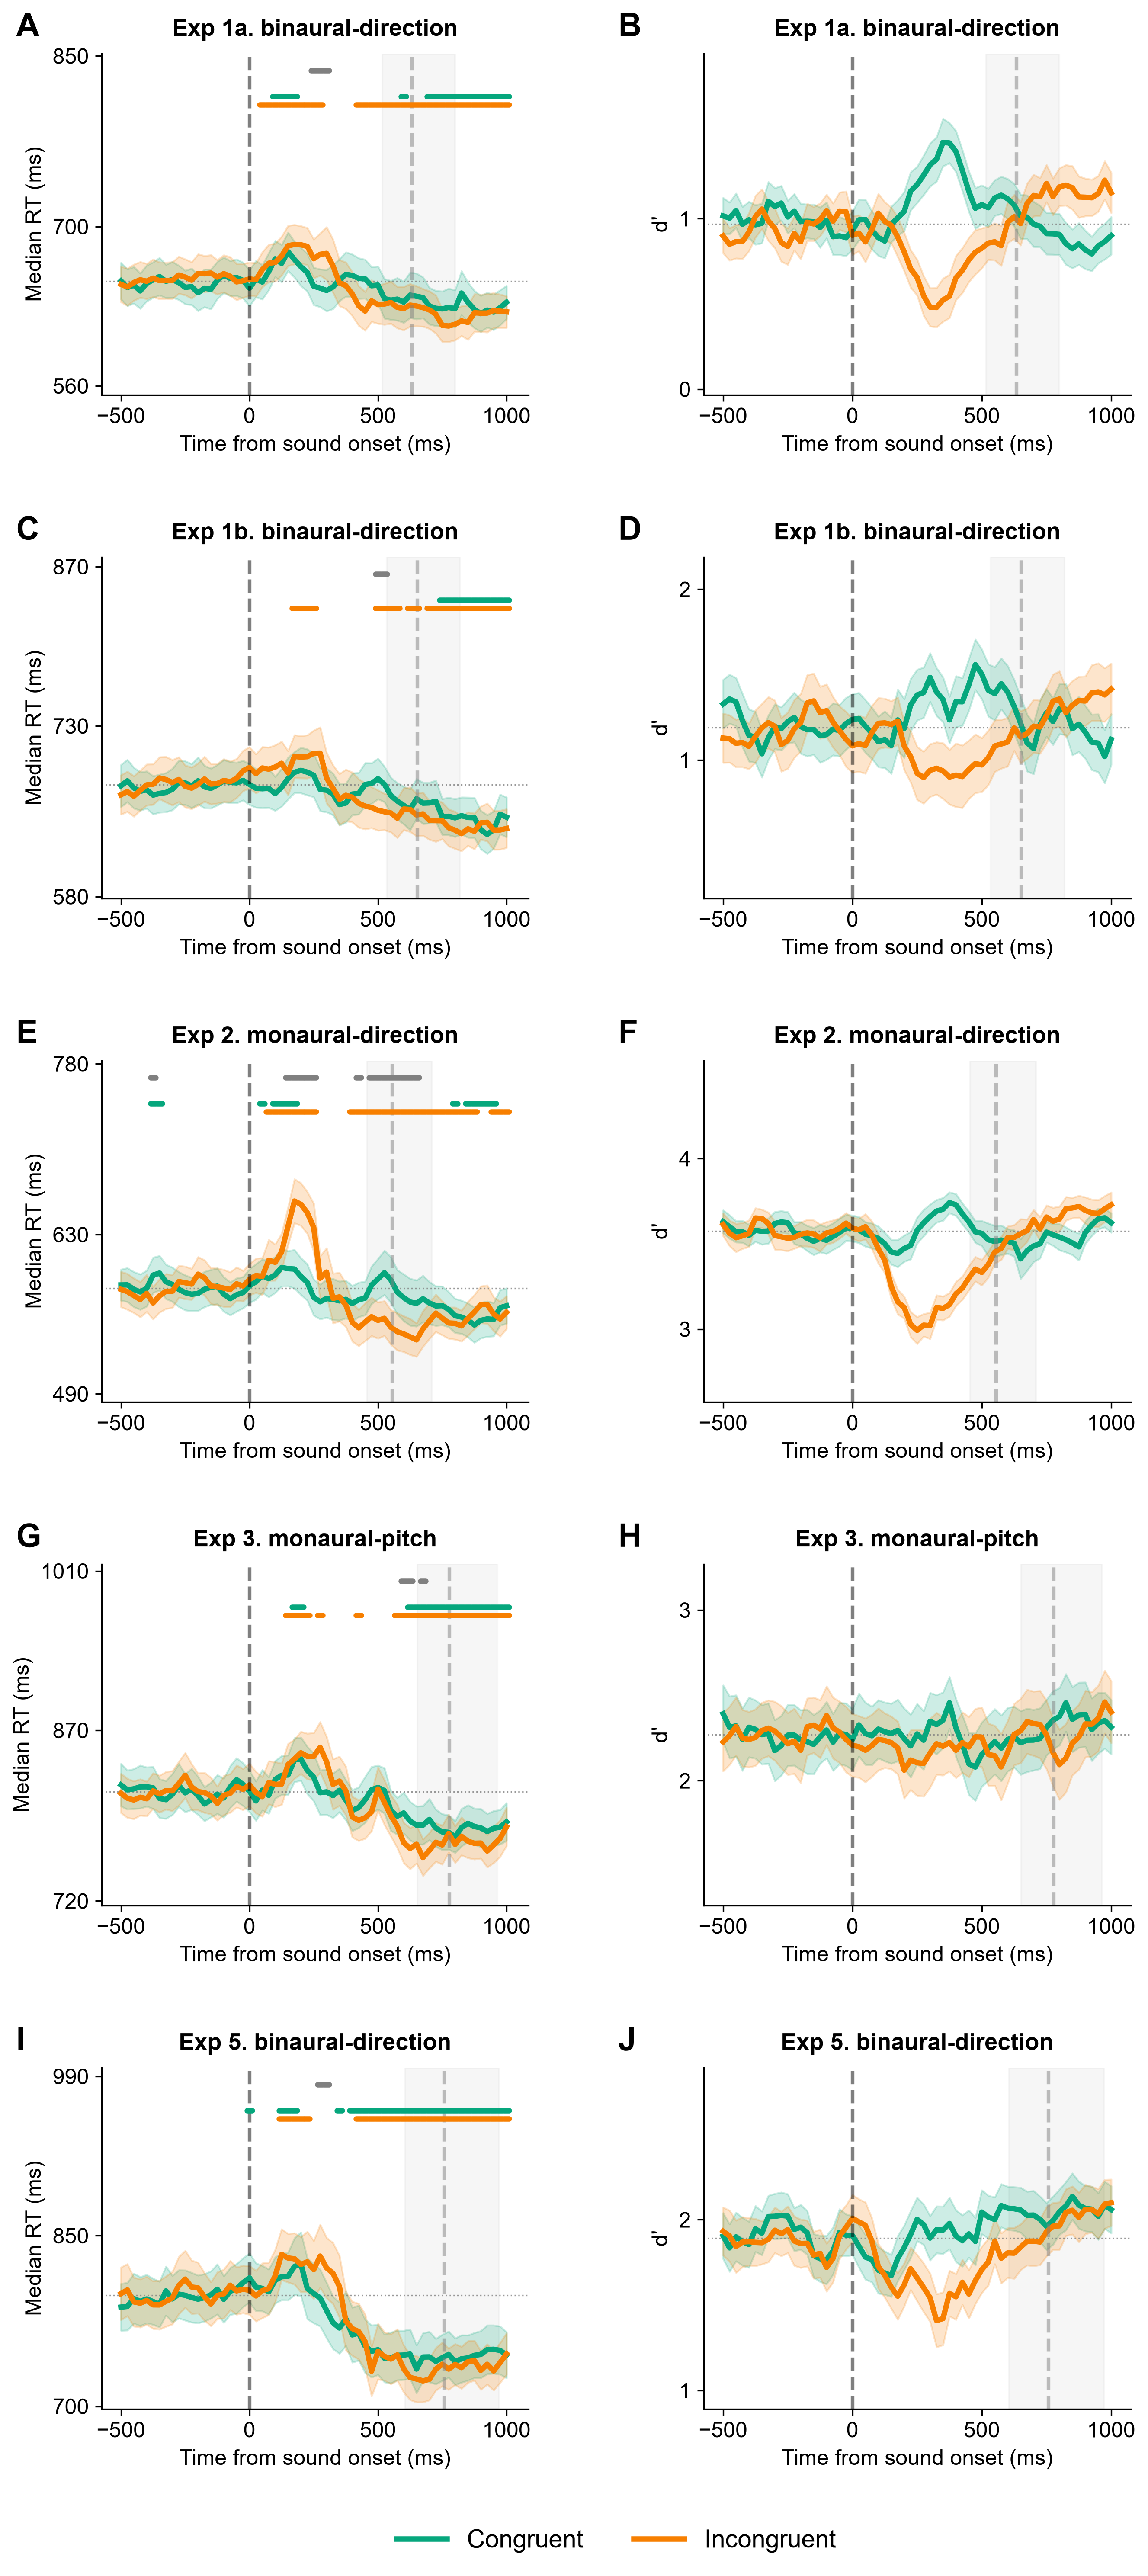

Saved summaries\plots\figureS2.png (+ .pdf)  (8.85 in wide = 61.4% of Figure 2's width -> insert at that fraction of Figure 2's printed width)


In [6]:
draw_grid(SOUND_COLUMNS, 'sound', 'figureS2')

## Figure S3 — response-locked saccade count and P(Correct Response)

Rows = experiments (Exp 1a, 1b, 2, 3, 5); left = saccade count, right = P(Correct Response); both
response-locked on responded sounds. Panel letters run row by row.

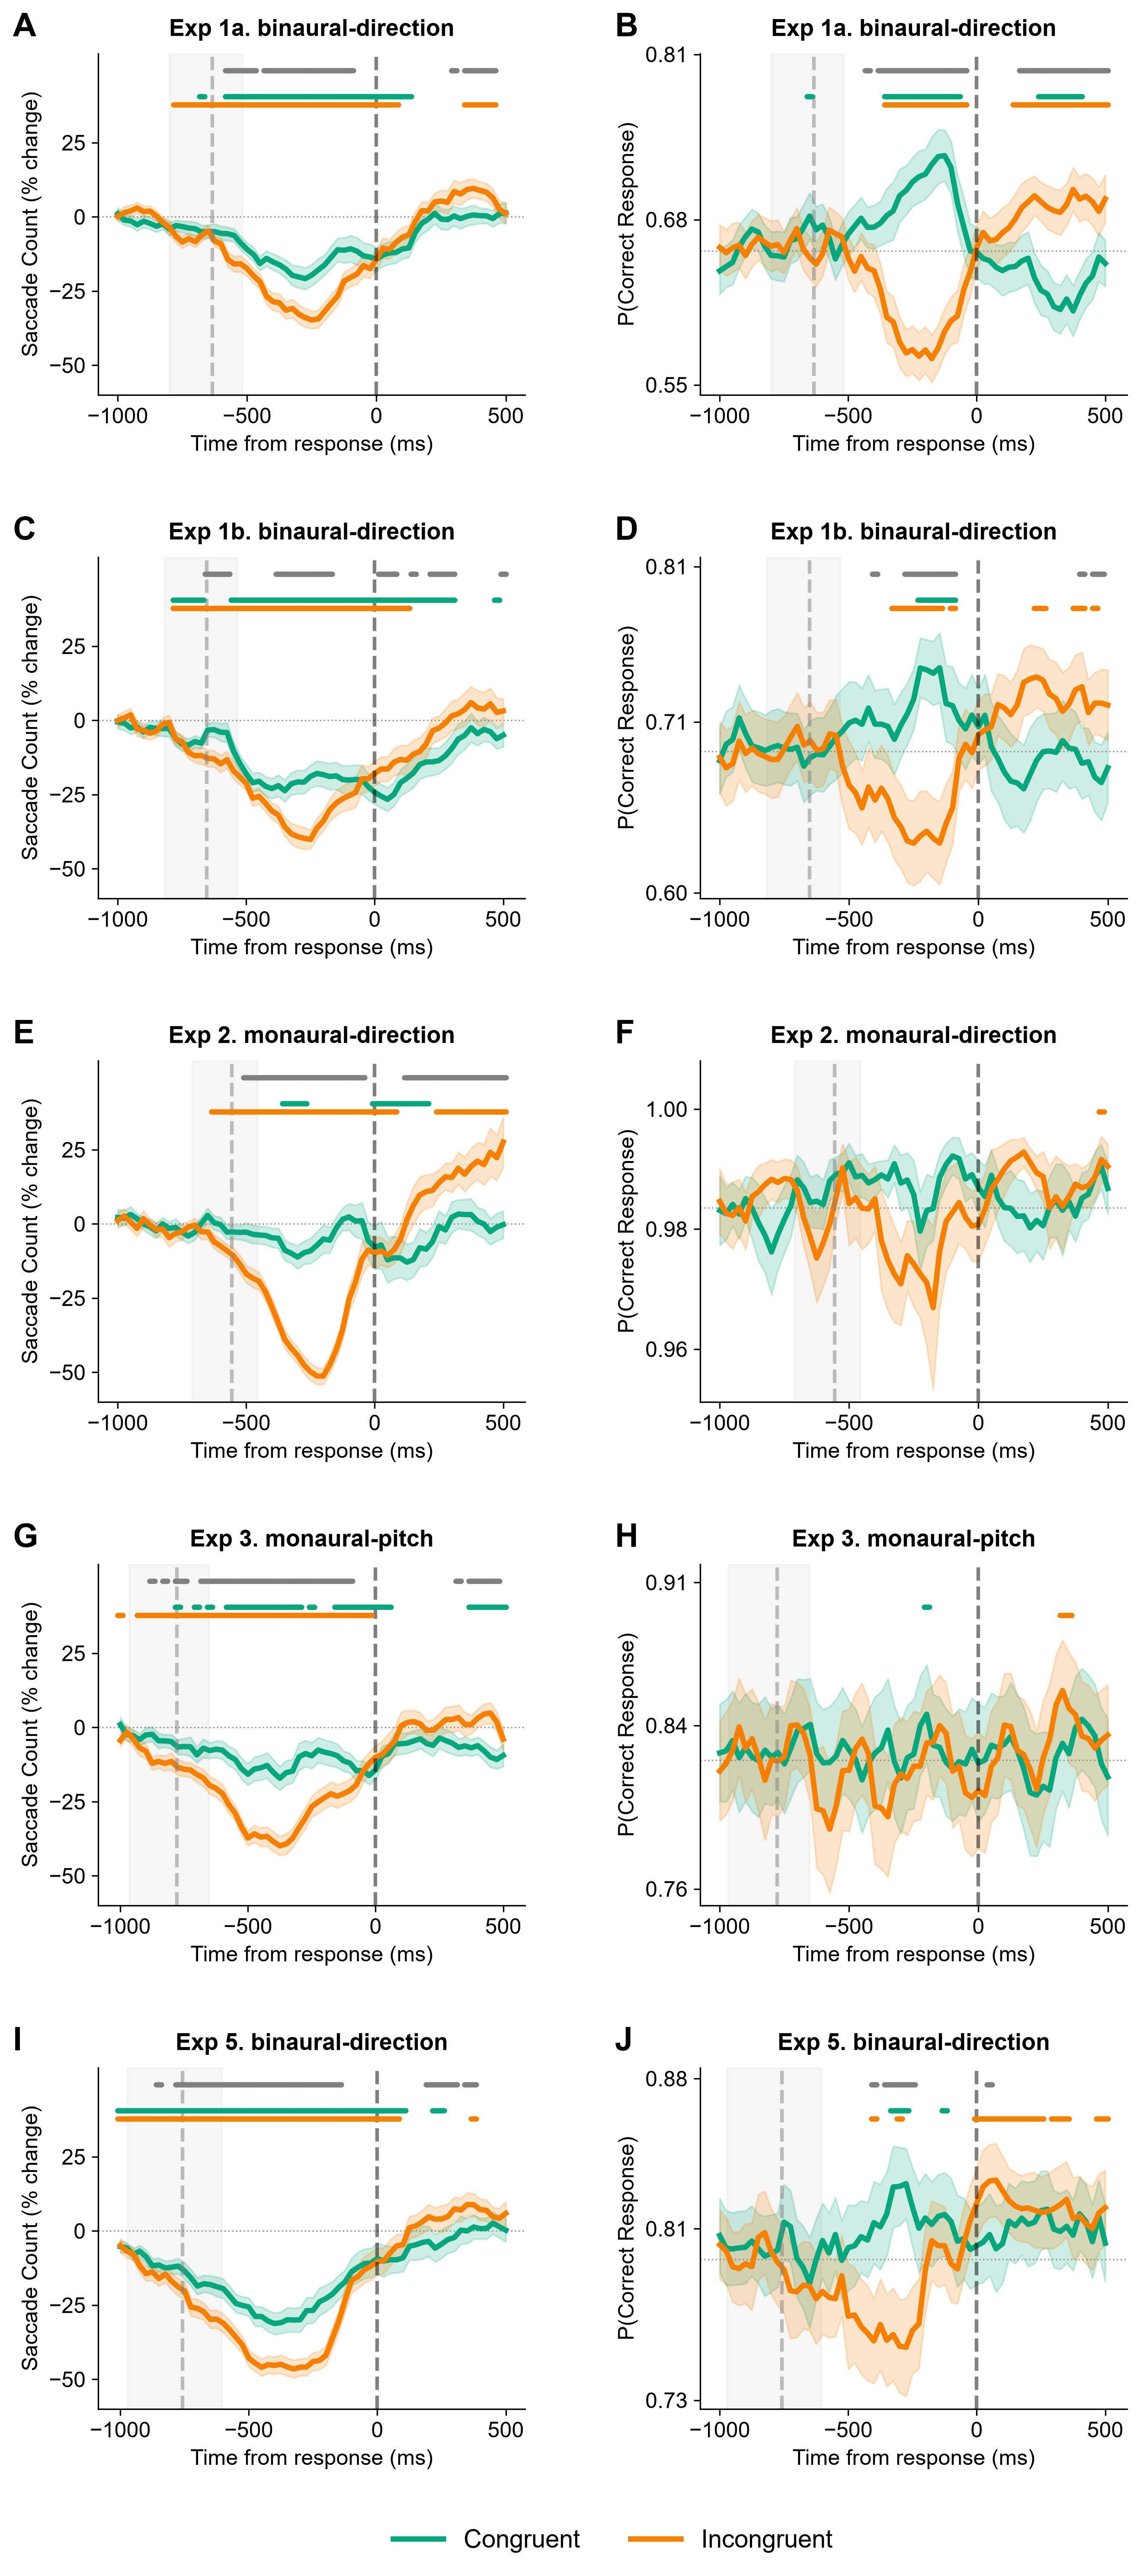

Saved summaries\plots\figureS3.png (+ .pdf)  (8.79 in wide = 61.0% of Figure 2's width -> insert at that fraction of Figure 2's printed width)


In [7]:
draw_grid(COLUMNS, 'response', 'figureS3')

## Reported values

The statistics behind Figure S3 (response-locked), as the manuscript quotes them
(`src/stats_report.py`). **Only windows before the response are reported** (window centre ≤
−half a window, so each window ends by the response). The FDR correction is the figure's, so p
values match the significance bars. P(correct) direction is measured against each subject's own
pre-sound value per condition (sound-locked, responded sounds) — what the vs-baseline test uses;
cached in `summaries/cache/figureS3_report_baselines.pkl`.

In [8]:
import stats_report as sr
importlib.reload(sr)

BASELINE_CACHE = Path('summaries') / 'cache' / 'figureS3_report_baselines.pkl'
_bl = {}
if BASELINE_CACHE.exists():
    with open(BASELINE_CACHE, 'rb') as _f:
        _bl = pickle.load(_f)
_new = False
for exp in EXPERIMENTS:
    key = (exp, cache_key(exp))
    if key not in _bl:
        data = table(exp)
        base = build_filter(data, include_response=True) & (data['response_given'] == 1)
        _bl[key] = sr.subject_baselines(data, {c: base & (data['consistent'] == v) for c, v in CONDITIONS},
                                        'p_correct_response', BASELINE_RANGE, BASELINE_REFERENCE)
        _new = True
if _new:
    with open(BASELINE_CACHE, 'wb') as _f:
        pickle.dump(_bl, _f)

rng = (TIME_RANGE[0], -WINDOW_SIZE / 2)
report_tables = []
for exp, label in EXPERIMENTS.items():
    b = bundles[exp]
    print(f"\n{label}: pre-sound P(correct), responded sounds = {b['pcr_centre']:.3f}")
    report_tables.append(sr.report(
        b['sig']['p_correct_response'], 'p_correct_response', b['results'],
        f'{label} - P(correct), response-locked', baselines=_bl[(exp, cache_key(exp))],
        step=STEP_SIZE, report_range=rng, extremes=(('max', rng), ('min', rng))))
    report_tables.append(sr.report(
        b['sig']['saccade_count_normalized_spec'], 'saccade_count_normalized_spec', b['results'],
        f'{label} - saccade count, response-locked', step=STEP_SIZE, report_range=rng,
        extremes=(('min', rng),)))


Exp 1a. binaural-direction: pre-sound P(correct), responded sounds = 0.655

Exp 1a. binaural-direction - P(correct), response-locked   [p_correct_response, n = 51]
  pre-sound level:  congruent 0.658,  incongruent 0.651
  congruent vs baseline              -650 ms  above baseline      mean Δ    +0.024   FDR p = 0.045
  congruent vs baseline          -350–-75 ms  above baseline      mean Δ    +0.050   FDR p < 0.001 to 0.022
  incongruent vs baseline        -350–-50 ms  below baseline      mean Δ    -0.062   FDR p < 0.001 to 0.031
  congruent vs incongruent       -425–-50 ms  congruent higher    mean Δ    +0.107   FDR p < 0.001 to 0.034
  congruent   max in -1000–-50 ms:  t = -125 ms,  0.730   (Δ from pre-sound +0.072)
  incongruent max in -1000–-50 ms:  t = -700 ms,  0.673   (Δ from pre-sound +0.022)
  congruent   min in -1000–-50 ms:  t = -1000 ms,  0.640   (Δ from pre-sound -0.019)
  incongruent min in -1000–-50 ms:  t = -175 ms,  0.571   (Δ from pre-sound -0.080)

Exp 1a. binaural-d